# Using injections for glitch and signal model training

In [ ]:
from mly.datatools import DataPod, DataSet, generator
import os
import numpy as np
import matplotlib.pyplot as plt
from mly.plugins import *
from scipy.signal import stft
%matplotlib inline

plt.rcParams['axes.titleweight'] = 'normal'   # subplot titles
plt.rcParams['font.size'] = 16

In [54]:
cbc_waveforms = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/cbc_waveform.pkl'
csg_lowfreq_waveforms = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_waveform_lowfreq.pkl'
csg_highfreq_waveforms = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_waveform_highfreq.pkl'
wnb_waveforms = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_waveform.pkl'
wnb_test_waveforms = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_test_waveform.pkl'

# PlugIn for Time-Frequency map

In [60]:
def stftGenFunction(strain, fs):
    stft_list = []
    for st in strain:
        f, t, Zxx = stft(st, fs=fs, nperseg=64, noverlap=32)
        Zxx_norm = np.abs(Zxx)
        stft_list.append(Zxx_norm)
    return np.array(stft_list), f, t

def stftPlotFunction(strain, fs, detectors, data=None):
    colors = {'H': 'Reds_r', 'L': 'Blues_r', 'V': 'Greens_r', 'K': 'Oranges_r', 'I': 'Purples_r'}
    Zxx_array, f, t = data

    n_det = len(detectors)
    fig, axes = plt.subplots(1, n_det, figsize=(6 * n_det, 6), sharey=True)

    if n_det == 1:
        axes = [axes]  # ensure axes is iterable even for a single detector

    for i, det in enumerate(detectors):
        im = axes[i].pcolormesh(t, f, Zxx_array[i], cmap=colors[det], shading='auto')
        axes[i].set_xlabel('Time (s)')
        axes[i].set_ylabel('Frequency (Hz)')
        axes[i].set_title(f'Detector {det}')
        axes[i].set_ylim(0, 512)
        fig.colorbar(im, ax=axes[i], label='Amplitude')

    plt.tight_layout()
    plt.show()

stft_plugin = PlugIn(name='stft',
                     genFunction=stftGenFunction,
                     attributes=['strain', 'fs'],
                     plotFunction=stftPlotFunction,
                     plotAttributes=['strain', 'fs', 'detectors'])

# Coherent WNB in detectors (Signal)

# 

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




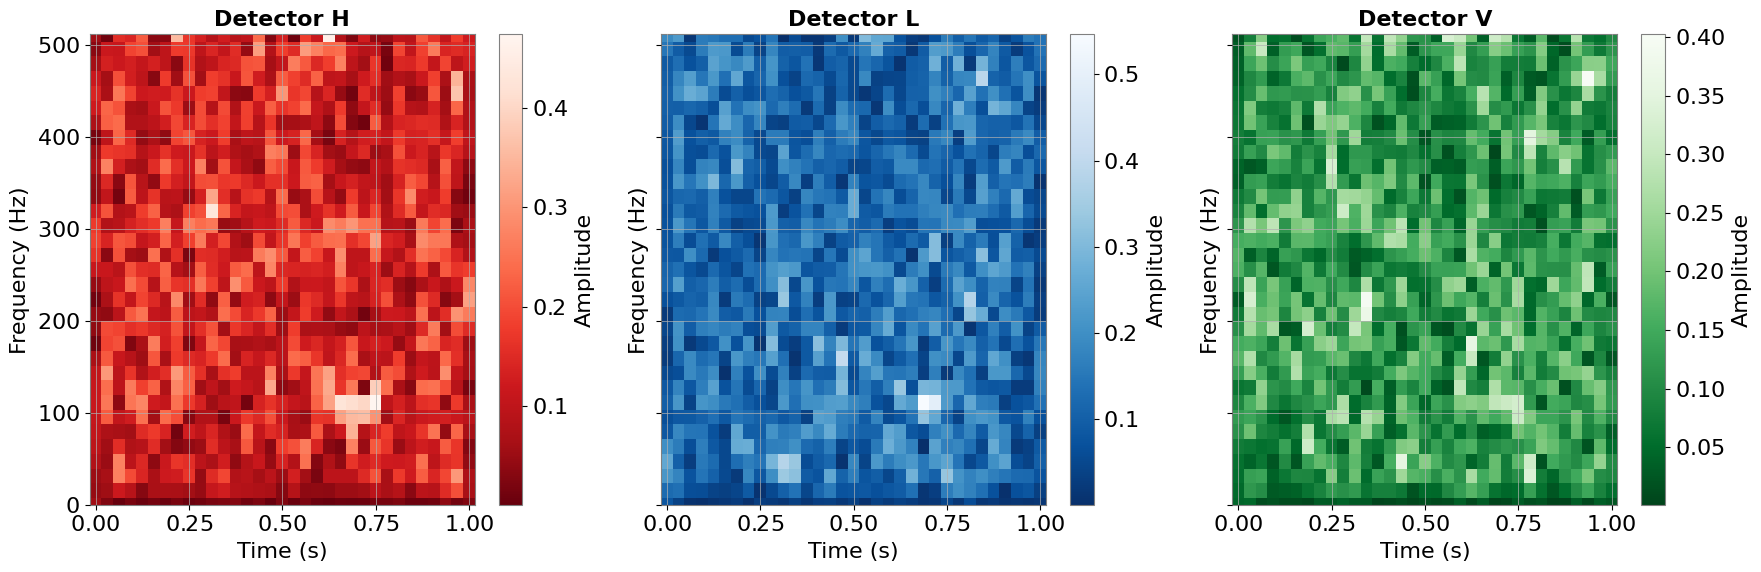

In [64]:
Set1 = generator(duration=1
                       ,fs=1024
                       ,size=1
                       ,labels = {'type' : 'signal'}
                       ,detectors = 'HLV'
                       ,backgroundType = 'optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       
                       #Injection mandatory parameters
                       
                       ,injection_source = wnb_waveforms
                       ,injectionSNR = (10, 30)

                       )

for pod in Set1:
    pod.addPlugIn(stft_plugin)
    
for pod in Set1:
    pod.plot('stft')

#Set1.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_signal_set.pkl')

# Glitch in one detector using WNB (Noise)

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




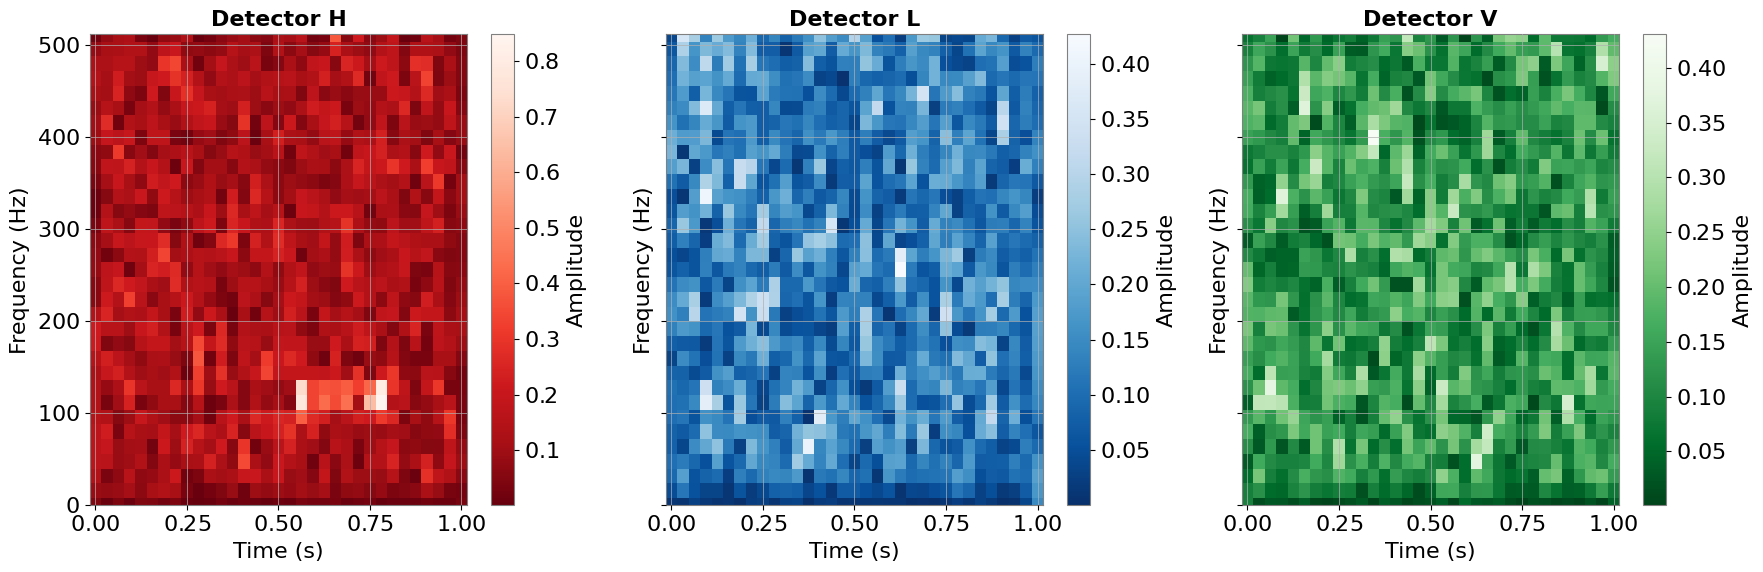

In [65]:
Set2 = generator(duration=1
                       ,fs=1024
                       ,size=1
                       ,labels = {'type' : 'noise'}
                       ,detectors = 'HLV'
                       ,backgroundType ='optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       #Inection mandatory parameters 
                       ,injection_source = wnb_waveforms
                       ,injectionSNR = (10, 30)
                       ,single = True
                    )

for pod in Set2:
    pod.addPlugIn(stft_plugin)
    
for pod in Set2:
    pod.plot('stft')
    
#Set2.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_glitch_set.pkl')

# No signal in any detector (Noise)

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




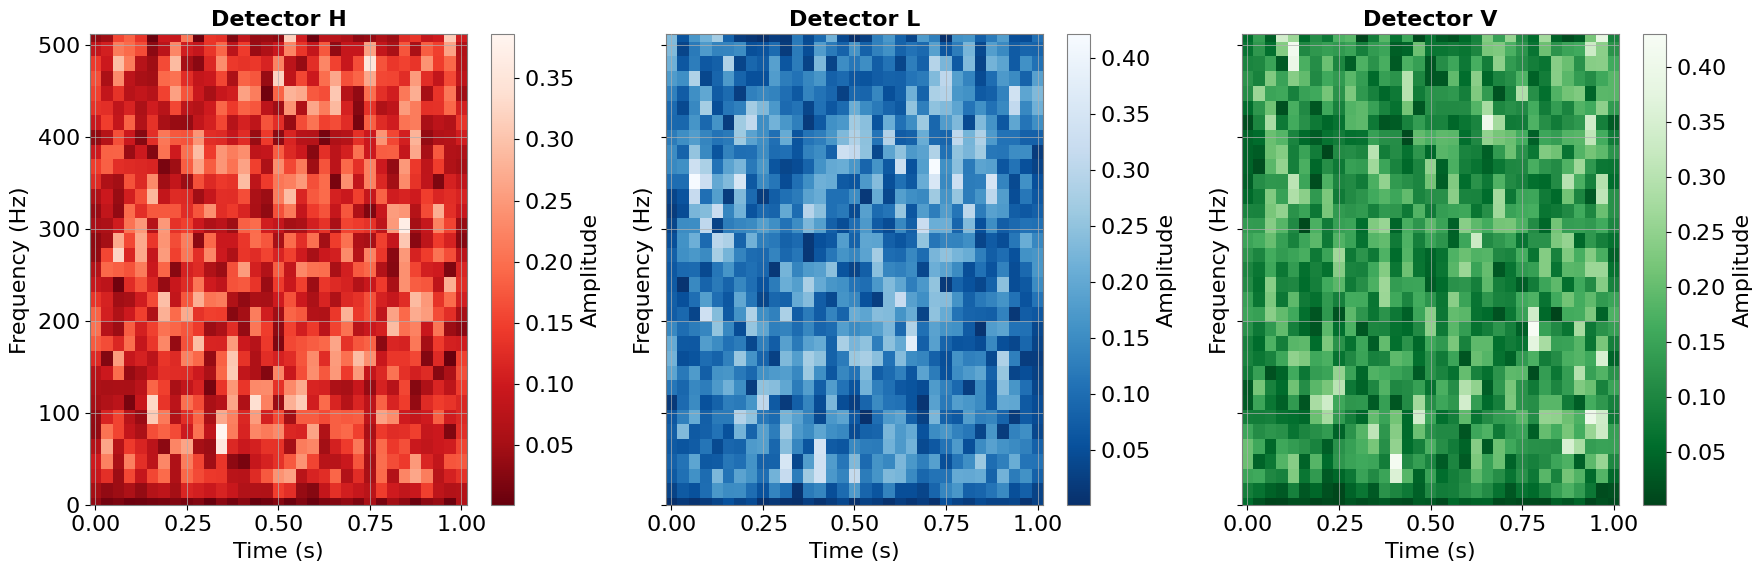

In [66]:
Set3 = generator(duration=1
                       ,fs=1024
                       ,size=1
                       ,detectors = 'HLV'
                       ,labels={'type':'noise'}
                       ,backgroundType ='optimal'
                       ,plugins = ['correlation_30'])

for pod in Set3:
    pod.addPlugIn(stft_plugin)

for pod in Set3:
    pod.plot('stft')
    
#Set3.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/gaussian_noise_set.pkl')

# Test data using CSG

In [8]:
Set4 = generator(duration=1
                       ,fs=1024
                       ,size=200
                       ,labels = {'type' : 'signal'}
                       ,detectors = 'HLV'
                       ,backgroundType ='optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       #Inection mandatory parameters 
                       ,injection_source = csg_lowfreq_waveforms
                       ,injectionSNR = (10, 30)
                    )

for pod in Set4:
    pod.addPlugIn(stft_plugin)
    
Set4.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_lowfreq_signal_set.pkl')

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




In [9]:
Set5 = generator(duration=1
                       ,fs=1024
                       ,size=200
                       ,labels = {'type' : 'signal'}
                       ,detectors = 'HLV'
                       ,backgroundType ='optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       #Inection mandatory parameters 
                       ,injection_source = csg_highfreq_waveforms
                       ,injectionSNR = (10, 30)
                    )

for pod in Set5:
    pod.addPlugIn(stft_plugin)
    
Set5.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_highfreq_signal_set.pkl')

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




In [10]:
Set6 = generator(duration=1
                       ,fs=1024
                       ,size=200
                       ,labels = {'type' : 'noise'}
                       ,detectors = 'HLV'
                       ,backgroundType ='optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       #Inection mandatory parameters 
                       ,injection_source = csg_lowfreq_waveforms
                       ,injectionSNR = (10, 30)
                       ,single=True
                    )

for pod in Set6:
    pod.addPlugIn(stft_plugin)
    
Set6.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_lowfreq_glitch_set.pkl')

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




In [11]:
Set7 = generator(duration=1
                       ,fs=1024
                       ,size=200
                       ,labels = {'type' : 'noise'}
                       ,detectors = 'HLV'
                       ,backgroundType ='optimal'
                       ,windowSize = 16
                       ,plugins = ['correlation_30']
                       #Inection mandatory parameters 
                       ,injection_source = csg_highfreq_waveforms
                       ,injectionSNR = (10, 30)
                       ,single=True
                    )

for pod in Set7:
    pod.addPlugIn(stft_plugin)
    
Set7.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_highfreq_glitch_set.pkl')

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




# Creating SNR signals for test using fixed FAR

In [5]:
base_path = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/'
snr_values = [0, 2, 5, 8, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50]
signal_type = {
    'highfreq' : csg_highfreq_waveforms,
    'lowfreq' : csg_lowfreq_waveforms,
    'cbc' : cbc_waveforms,
    'wnb_test' : wnb_test_waveforms}

for snr in snr_values:
    for sig_name, sig_waveforms in signal_type.items():
        dataset = generator(
            duration=1,
            fs=1024,
            size=150,
            labels={'type': 'signal'},
            detectors='HLV',
            backgroundType='real',
            noiseSourceFile = '/home/vasileios.skliris/buffer_set_O3b_10000.pkl',
            windowSize=16,
            plugins=['correlation_30'],
            injection_source=sig_waveforms,
            injectionSNR=(snr),
        )
        for pod in dataset:
            pod.addPlugIn(stft_plugin)
    
        filename = f'{base_path}{sig_name}_test_set_noise_snr{snr}.pkl'
        dataset.save(filename)

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}




profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}


profiles {'H': 'ali

# Noise test

In [12]:
os.environ["GWDATAFIND_SERVER"]="datafind.ldas.cit:80"

SET = generator(
duration = 1
,fs = 1024
,size = 20
,detectors = 'HLV'
,labels = {'type': 'UNDEFINED'}
,backgroundType = 'real'
,noiseSourceFile = [[1248705620.0, 1248709235.0],[1248705620.0, 1248709235.0],[1248705620.0, 1248709235.0]]
,windowSize = 16
,timelags = 10
,startingPoint = None
,name = '1248705620-1248709235_3600_H'
,frames ={'H': 'H1_HOFT_C01', 'L': 'L1_HOFT_C01', 'V': 'V1Online'}
,channels ={'H': 'H1:DCS-CALIB_STRAIN_C01', 'L': 'L1:DCS-CALIB_STRAIN_C01', 'V': 'V1:Hrec_hoft_16384Hz'}
,whitening_config ={'method': 'welch', 'fftlength': 4, 'overlap': 2, 'f_min': 20, 'f_max': 512, 'processing_window': [13, 14]}
,shuffle=False)


for pod in SET:
        pod.addPlugIn(stft_plugin)

SET.save('/home/jakub.rutkowski/project/waveform-generation/waveform-sets/real_noise_set_test_20.pkl')

profiles {'H': 'aligo', 'L': 'aligo', 'V': 'avirgo', 'K': 'KAGRA_Early', 'I': 'aligo'}



 time to get H data : 13.523886442184448
Success on getting the H data.

 time to get L data : 8.995259523391724
Success on getting the L data.

 time to get V data : 26.988481760025024
Success on getting the V data.


